MULTI-LAYER PERCEPTRON FROM SCRATCH
Adapted from original notebook from Vítor Gama Lemos

[kaggle-notebook](https://www.kaggle.com/code/vitorgamalemos/multilayer-perceptron-from-scratch)


In [1]:
import random
import seaborn
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.cm as cm

seaborn.set(style='whitegrid'); seaborn.set_context('talk')
%matplotlib inline
%config InlineBackend.figure_format = 'retina'

from sklearn.datasets import load_iris
iris_data = load_iris()

In [2]:
print(iris_data['DESCR'])

.. _iris_dataset:

Iris plants dataset
--------------------

**Data Set Characteristics:**

:Number of Instances: 150 (50 in each of three classes)
:Number of Attributes: 4 numeric, predictive attributes and the class
:Attribute Information:
    - sepal length in cm
    - sepal width in cm
    - petal length in cm
    - petal width in cm
    - class:
            - Iris-Setosa
            - Iris-Versicolour
            - Iris-Virginica

:Summary Statistics:

============== ==== ==== ======= ===== ====================
                Min  Max   Mean    SD   Class Correlation
============== ==== ==== ======= ===== ====================
sepal length:   4.3  7.9   5.84   0.83    0.7826
sepal width:    2.0  4.4   3.05   0.43   -0.4194
petal length:   1.0  6.9   3.76   1.76    0.9490  (high!)
petal width:    0.1  2.5   1.20   0.76    0.9565  (high!)
============== ==== ==== ======= ===== ====================

:Missing Attribute Values: None
:Class Distribution: 33.3% for each of 3 classes.
:Cr

Number of samples: 150
Number of features: 4 



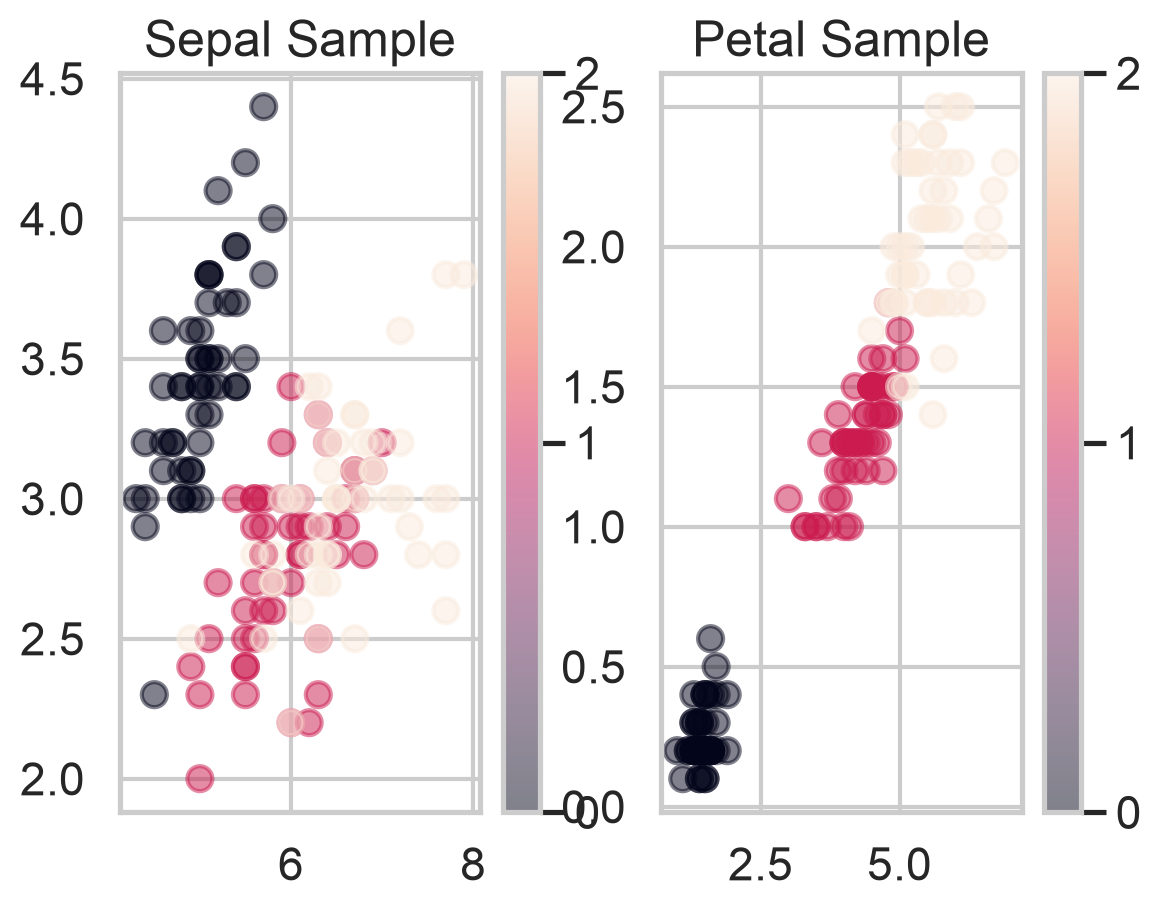

In [3]:
n_samples, n_features = iris_data.data.shape

print(f"Number of samples: {n_samples}")
print(f"Number of features: {n_features} \n")

plt.subplot(1, 2, 1)
scatter_plot = plt.scatter(iris_data.data[:,0], iris_data.data[:,1], alpha=0.5,
                           c=iris_data.target)
plt.colorbar(ticks=([0, 1, 2]))
plt.title('Sepal Sample');

plt.subplot(1, 2, 2)
scatter_plot_2 = plt.scatter(iris_data.data[:,2], iris_data.data[:,3], alpha=0.5,
                           c=iris_data.target)
plt.colorbar(ticks=([0, 1, 2]))
plt.title('Petal Sample');

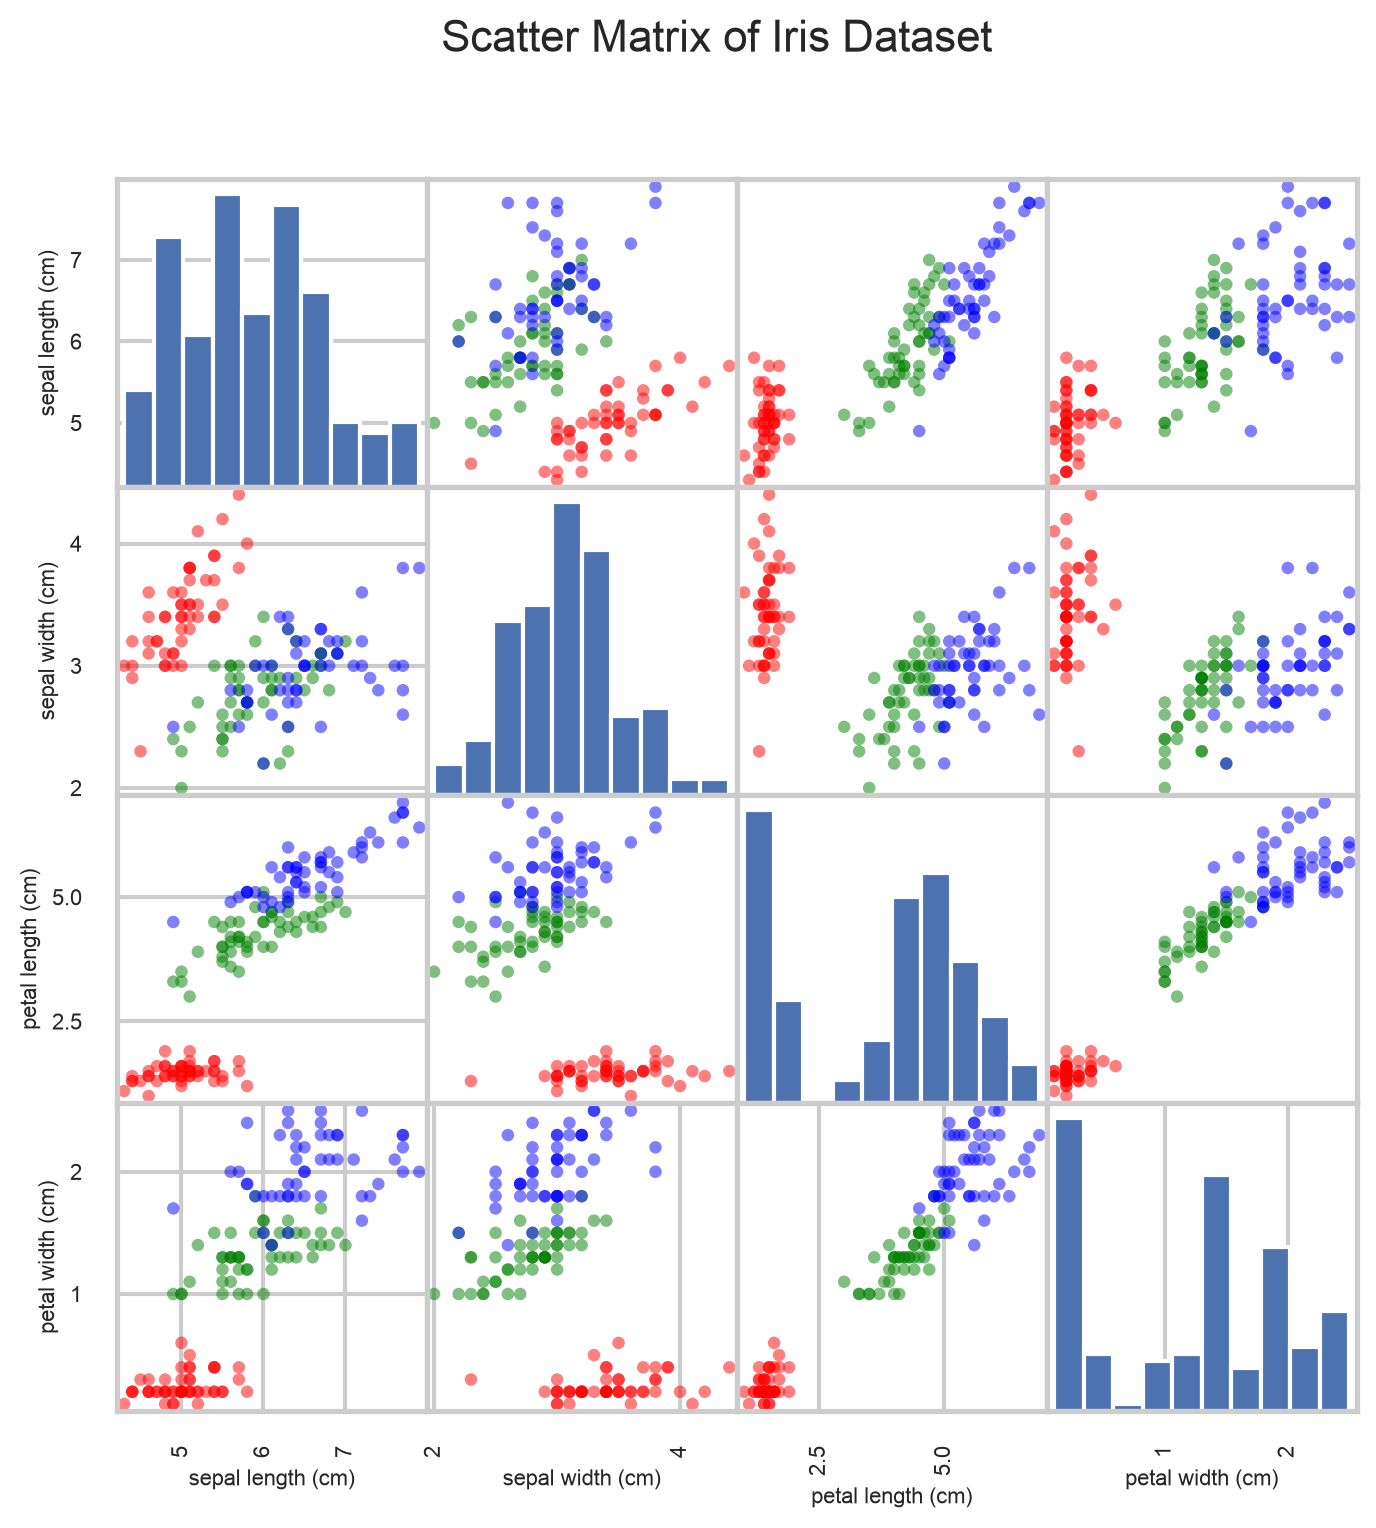

In [4]:
import pandas
from pandas.plotting import scatter_matrix


# Cria um DataFrame com os dados e os nomes das colunas
df = pd.DataFrame(iris_data.data, columns=iris_data.feature_names)
df['target'] = iris_data.target

# Mapeia os números das classes para nomes legíveis
target_names = iris_data.target_names
df['target_name'] = df['target'].apply(lambda i: target_names[i])

# Escolhe uma paleta de cores
colors = {'setosa': 'red', 'versicolor': 'green', 'virginica': 'blue'}
df['color'] = df['target_name'].map(colors)

# Gera o scatter_matrix
axes = scatter_matrix(df[iris_data.feature_names],
               figsize=(8, 8),
               diagonal='hist',
               color=df['color'],
               alpha=0.5)

# Reduz o tamanho da fonte dos rótulos dos eixos
for ax in axes.ravel():
    ax.set_xlabel(ax.get_xlabel(), fontsize=8)
    ax.set_ylabel(ax.get_ylabel(), fontsize=8)

plt.suptitle("Scatter Matrix of Iris Dataset", fontsize=16)
plt.show()

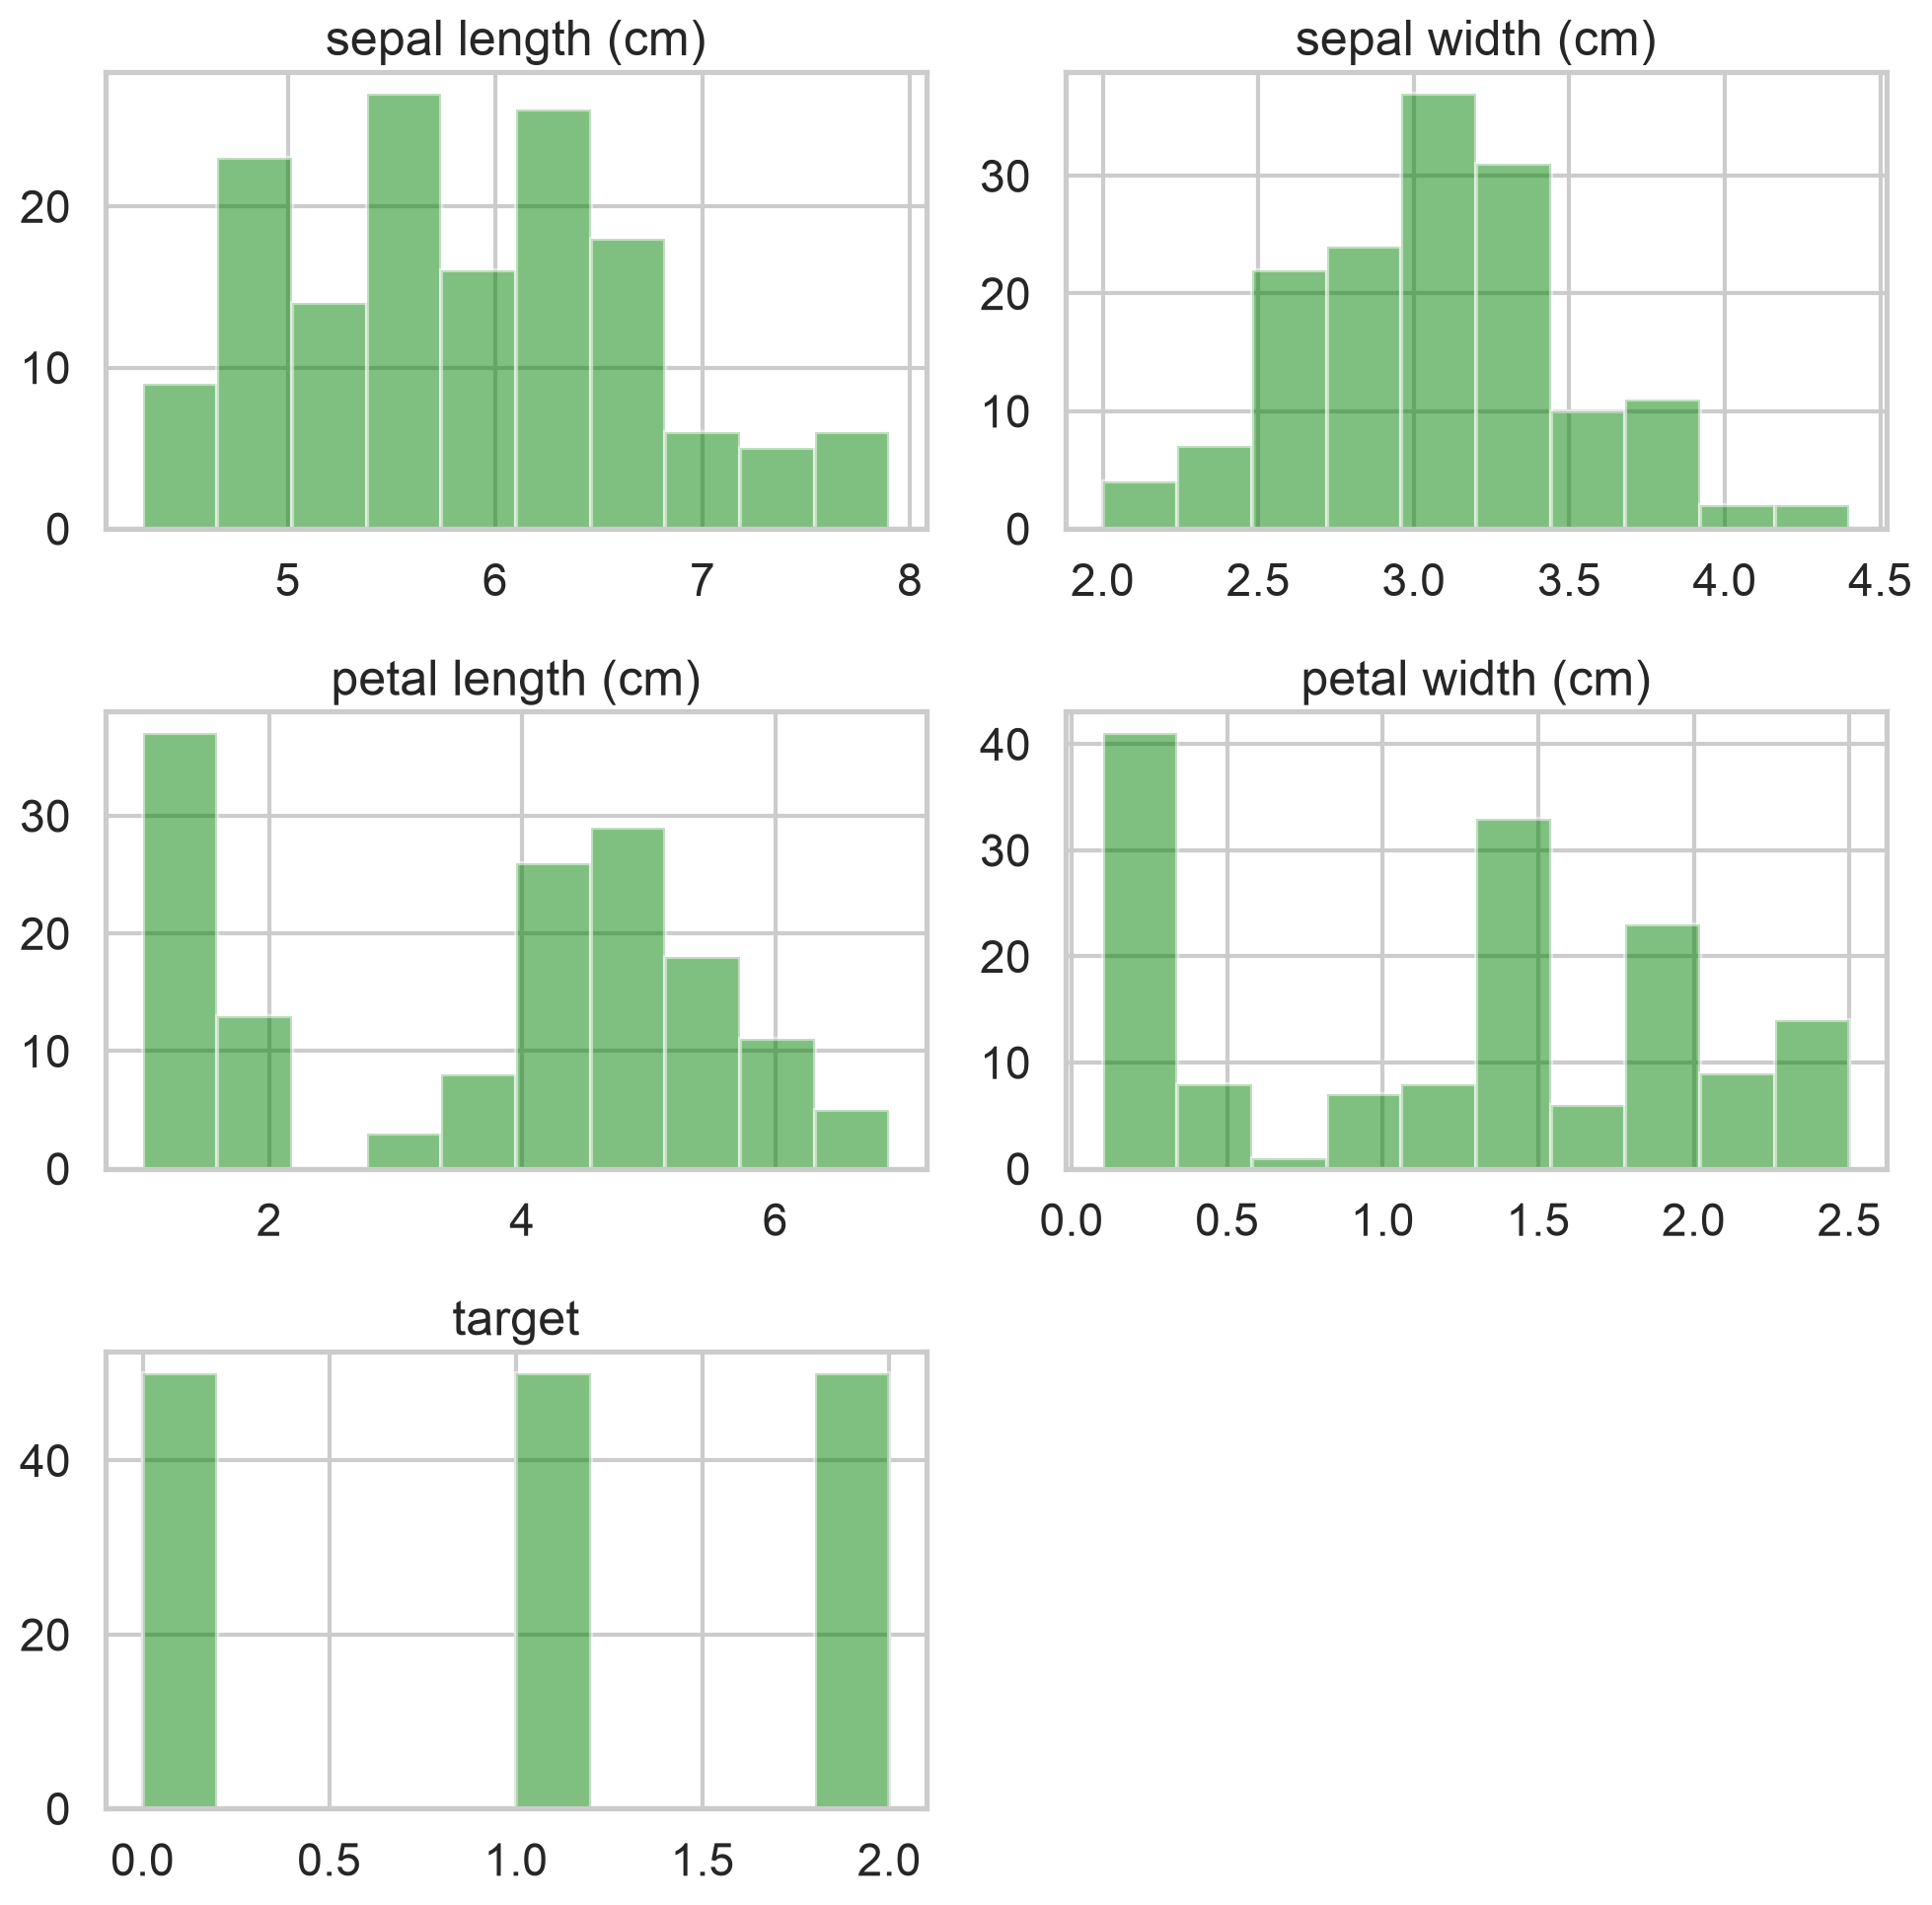

In [5]:
axes = df.hist(alpha=0.5, figsize=(10, 10), color='green')

plt.tight_layout()
plt.show()

In [15]:
import numpy as np
import random
from sklearn.model_selection import train_test_split
from sklearn.datasets import load_iris

# Load the Iris dataset
iris_data = load_iris()

# Join features and labels into a single array
iris_dataset = np.column_stack((iris_data.data, iris_data.target.T))  # shape (150, 5)

# Shuffle the dataset (optional: for reproducibility)
random.seed(123)
random.shuffle(iris_dataset)

# Split features (X) and labels (y)
X = np.array([i[:4] for i in iris_dataset])  # shape (150, 4)
y = np.array([i[4] for i in iris_dataset])   # shape (150,)

# Use train_test_split to divide into 80% train, 20% test
train_X, test_X, train_y, test_y = train_test_split(
    X, y,
    test_size=0.2,
    random_state=11,  # set for reproducibility
    stratify=y        # keep label proportions balanced
)

# Now you have train_X, train_y, test_X, test_y ready

print(test_y)

[0. 0. 0. 1. 1. 0. 1. 0. 1. 0. 0. 1. 0. 0. 1. 0. 1. 0. 0. 2. 0. 0. 1. 0.
 0. 1. 0. 0. 0. 0.]


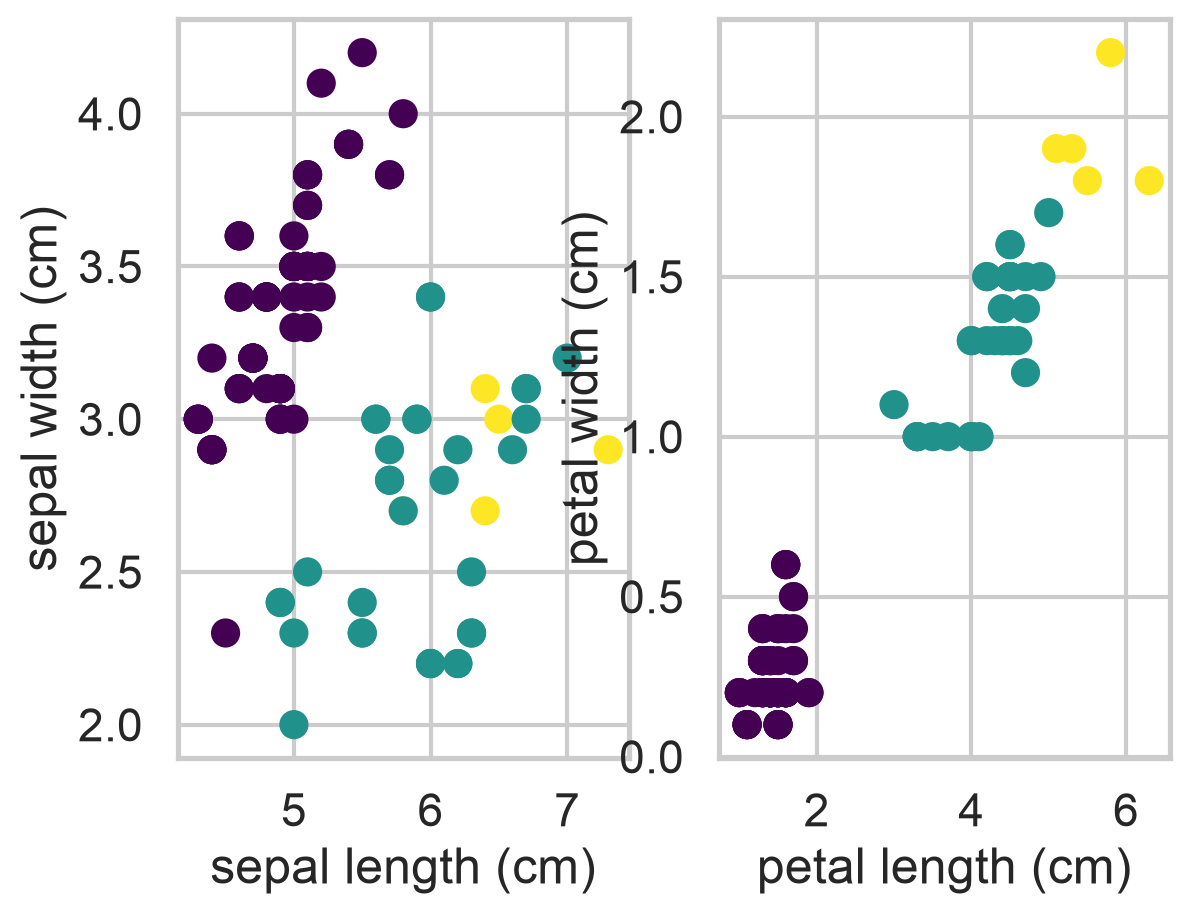

In [7]:
import matplotlib.pyplot as plt
import matplotlib.cm as cm

# Plot training Samples

plt.subplot(1, 2, 1)
plt.scatter(train_X[:,0],train_X[:,1],c=train_y,cmap=cm.viridis)
plt.xlabel(iris_data.feature_names[0])
plt.ylabel(iris_data.feature_names[1])

plt.subplot(1, 2, 2)
plt.scatter(train_X[:,2],train_X[:,3],c=train_y,cmap=cm.viridis)
plt.xlabel(iris_data.feature_names[2])
plt.ylabel(iris_data.feature_names[3]);

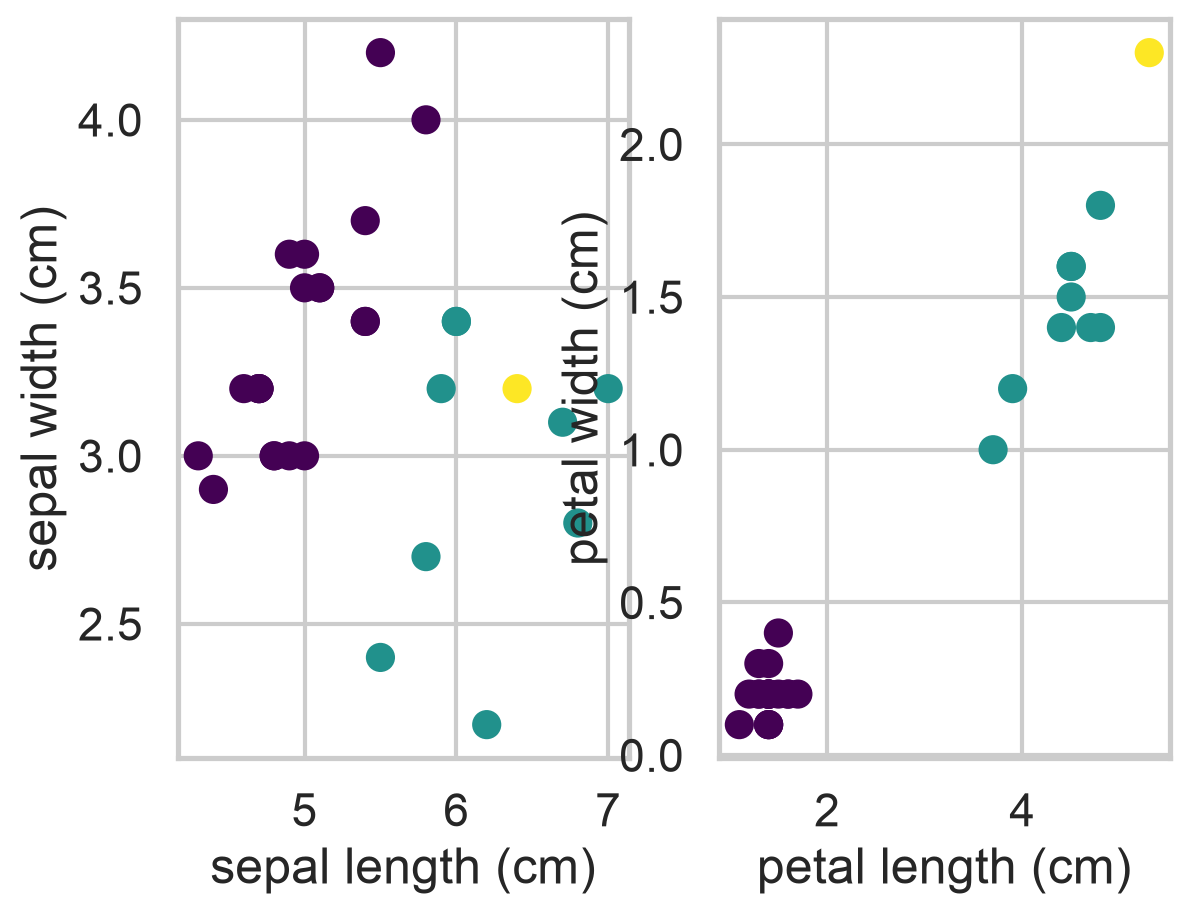

In [8]:
# Plot test samples
plt.subplot(1, 2, 1)
plt.scatter(test_X[:,0],test_X[:,1],c=test_y,cmap=cm.viridis)
plt.xlabel(iris_data.feature_names[0])
plt.ylabel(iris_data.feature_names[1])

plt.subplot(1, 2, 2)
plt.scatter(test_X[:,2],test_X[:,3],c=test_y,cmap=cm.viridis)
plt.xlabel(iris_data.feature_names[2])
plt.ylabel(iris_data.feature_names[3]);

In [ ]:
# Implementation the Multilayer Perceptron in Python
from sklearn.base import BaseEstimator, ClassifierMixin, RegressorMixin
import random
import numpy as np
import matplotlib.pyplot as plt

class MultiLayerPerceptron(BaseEstimator, ClassifierMixin):

    def __init__(self, params=None):
        # Store the params argument to satisfy BaseEstimator requirements
        self.params = params

        if (params == None):
            self.inputLayer = 4                        # Input Layer
            self.hiddenLayer = 5                       # Hidden Layer
            self.outputLayer = 3                       # Outpuy Layer
            self.learningRate = 0.005                  # Learning rate
            self.max_epochs = 600                      # Epochs
            self.iasHiddenValue = -1                   # Bias HiddenLayer
            self.BiasOutputValue = -1                  # Bias OutputLayer
            self.activation = self.ativacao['sigmoid'] # Activation function
            self.deriv = self.derivada['sigmoid']
        else:
            self.inputLayer = params['InputLayer']
            self.hiddenLayer = params['HiddenLayer']
            self.outputLayer = params['OutputLayer']
            self.learningRate = params['LearningRate']
            self.max_epochs = params['Epocas']
            self.BiasHiddenValue = params['BiasHiddenValue']
            self.BiasOutputValue = params['BiasOutputValue']
            self.activation = self.ativacao[params['ActivationFunction']]
            self.deriv = self.derivada[params['ActivationFunction']]

        # Starting Bias and Weights
        # assign ramdom values [-1 .. +1] in order to start with some weights
        # not so symmetric
        # Weight initialization: passing correct arguments to starting_weights
        self.WEIGHT_hidden = self.starting_weights(self.inputLayer, self.hiddenLayer)
        self.WEIGHT_output = self.starting_weights(self.hiddenLayer, self.outputLayer)

        self.BIAS_hidden = np.array([self.BiasHiddenValue for i in range(self.hiddenLayer)])
        self.BIAS_output = np.array([self.BiasOutputValue for i in range(self.outputLayer)]) # Corrected attribute name
        self.classes_number = 3

    pass

    # This function creates a 2D matrix of random values between -1 and +1
    # Shape: rows x columns
    def starting_weights(self, rows, columns):
        return [[2  * random.random() - 1 for _ in range(columns)] for _ in range(rows)]

    ativacao = {
         'sigmoid': (lambda x: 1/(1 + np.exp(-x))),
            'tanh': (lambda x: np.tanh(x)),
            'Relu': (lambda x: x*(x > 0)),
               }
    derivada = {
         'sigmoid': (lambda x: x*(1-x)),
            'tanh': (lambda x: 1-x**2),
            'Relu': (lambda x: 1 * (x>0))
               }

    # This calculates the error at the output layer and then propagates it
    # backward through the network to update the weights in each layer
    def Backpropagation_Algorithm(self, x):
        DELTA_output = []
        # Stage 1 - Error: OutputLayer (target - predicted)
        ERROR_output = self.output - self.OUTPUT_L2
        DELTA_output = ((-1)*(ERROR_output) * self.deriv(self.OUTPUT_L2))

        arrayStore = []
        # Stage 2 - Update weights OutputLayer and HiddenLayer
        for i in range(self.hiddenLayer):
            for j in range(self.outputLayer): # Corrected attribute name
                self.WEIGHT_output[i][j] -= (self.learningRate * (DELTA_output[j] * self.OUTPUT_L1[i]))
                self.BIAS_output[j] -= (self.learningRate * DELTA_output[j])

        # Stage 3 - Error: HiddenLayer
        delta_hidden = np.matmul(self.WEIGHT_output, DELTA_output)* self.deriv(self.OUTPUT_L1)

        # Stage 4 - Update weights HiddenLayer and InputLayer(x)
        for i in range(self.inputLayer):
            for j in range(self.hiddenLayer):
                self.WEIGHT_hidden[i][j] -= (self.learningRate * (delta_hidden[j] * x[i]))
                self.BIAS_hidden[j] -= (self.learningRate * delta_hidden[j])



    def show_err_graphic(self,v_erro,v_epoca):
        plt.figure(figsize=(9,4))
        plt.plot(v_epoca, v_erro, color="b", marker=11)
        plt.xlabel("Number of Epochs")
        plt.ylabel("Squared error (MSE) ");
        plt.title("Error Minimization")
        plt.show()


    def predict(self, X, y):
        'Returns the predictions for every element of X'
        my_predictions = []
        'Forward Propagation'
        forward = np.matmul(X,self.WEIGHT_hidden) + self.BIAS_hidden
        forward = np.matmul(forward, self.WEIGHT_output) + self.BIAS_output
        for i in forward:
            my_predictions.append(max(enumerate(i), key=lambda x:x[1])[0])

        array_score = []
        for i in range(len(my_predictions)):
            if my_predictions[i] == 0:
                array_score.append([i, 'Iris-setosa', my_predictions[i], y[i]])
            elif my_predictions[i] == 1:
                 array_score.append([i, 'Iris-versicolour', my_predictions[i], y[i]])
            elif my_predictions[i] == 2:
                 array_score.append([i, 'Iris-virginica', my_predictions[i], y[i]])

        dataframe = pd.DataFrame(array_score, columns=['_id', 'class', 'output', 'hoped_output'])
        return my_predictions, dataframe

    def fit(self, X, y):
        count_epoch = 1
        total_error = 0
        n = len(X);
        epoch_array = []
        error_array = []
        # Initialize lists to store specific weight values for plotting
        weight_over_epochs_W0_plot = []
        weight_over_epochs_W1_plot = []


        while(count_epoch <= self.max_epochs):
            for idx,inputs in enumerate(X):
                self.output = np.zeros(self.classes_number)
                'Stage 1 - (Forward Propagation)'
                self.OUTPUT_L1 = self.activation((np.dot(inputs, self.WEIGHT_hidden) + self.BIAS_hidden))
                self.OUTPUT_L2 = self.activation((np.dot(self.OUTPUT_L1, self.WEIGHT_output) + self.BIAS_output))
                'Stage 2 - One-Hot-Encoding'
                if(y[idx] == 0):
                    self.output = np.array([1,0,0]) #Class1 {1,0,0}
                elif(y[idx] == 1):
                    self.output = np.array([0,1,0]) #Class2 {0,1,0}
                elif(y[idx] == 2):
                    self.output = np.array([0,0,1]) #Class3 {0,0,1}

                square_error = 0
                for i in range(self.outputLayer):
                    erro = (self.output[i] - self.OUTPUT_L2[i])**2
                    square_error = (square_error + (0.05 * erro))
                    total_error = total_error + square_error

                'Backpropagation : Update Weights'
                self.Backpropagation_Algorithm(inputs)

            # The original code calculates total_error per batch, then divides by n (number of samples).
            # It's more standard to calculate the mean squared error per epoch by summing errors over
            # all samples in the epoch and then dividing by the number of output neurons.
            # Keeping the original logic for total_error calculation, but this is not
            # a standard MSE calculation.
            total_error = (total_error / n)
            if((count_epoch % 50 == 0)or(count_epoch == 1)):
                print("Epoch ", count_epoch, "- Total Error: ",total_error)
                error_array.append(total_error)
                epoch_array.append(count_epoch)
                # Append the specific weight values only when we are recording the epoch
                weight_over_epochs_W0_plot.append(self.WEIGHT_hidden[0][0])
                weight_over_epochs_W1_plot.append(self.WEIGHT_output[0][0])


            # Reset total_error for the next epoch
            total_error = 0

            count_epoch += 1
        self.show_err_graphic(error_array,epoch_array)

        # Plot the change of a *single* weight over the epochs that were recorded
        plt.figure(figsize=(8, 4))
        # Use the new lists which have the same length as epoch_array
        plt.plot(epoch_array, weight_over_epochs_W0_plot, label='Weight[0][0]')
        plt.title('Change of a Sample Weight (Input 0 to Hidden 0) over Epochs')
        plt.xlabel('Number of Epochs')
        plt.ylabel('Weight Value')
        plt.legend()
        plt.show()

        plt.figure(figsize=(8, 4))
        # Use the new lists which have the same length as epoch_array
        plt.plot(epoch_array, weight_over_epochs_W1_plot, label='Weight[0][0]')
        plt.title('Change of a Sample Weight (Hidden 0 to Output 0) over Epochs')
        plt.xlabel('Number of Epochs')
        plt.ylabel('Weight Value')
        plt.legend()
        plt.show()


        return self

Epoch  1 - Total Error:  0.06758981166881102
Epoch  50 - Total Error:  0.04024720417130557
Epoch  100 - Total Error:  0.02286486557652496
Epoch  150 - Total Error:  0.01327635286206625
Epoch  200 - Total Error:  0.009687618408255078
Epoch  250 - Total Error:  0.008328459058811613
Epoch  300 - Total Error:  0.00761468849032985
Epoch  350 - Total Error:  0.007178426628736327
Epoch  400 - Total Error:  0.0068849363253296655
Epoch  450 - Total Error:  0.006674112495662894
Epoch  500 - Total Error:  0.0065154558916519925
Epoch  550 - Total Error:  0.006391971206018784
Epoch  600 - Total Error:  0.006293445523627044
Epoch  650 - Total Error:  0.006213323972163784
Epoch  700 - Total Error:  0.00614715062622757
Epoch  750 - Total Error:  0.006091753825413658
Epoch  800 - Total Error:  0.006044802234347228
Epoch  850 - Total Error:  0.006004547869273663
Epoch  900 - Total Error:  0.0059696645270964875
Epoch  950 - Total Error:  0.0059391375688427886
Epoch  1000 - Total Error:  0.005912184529414

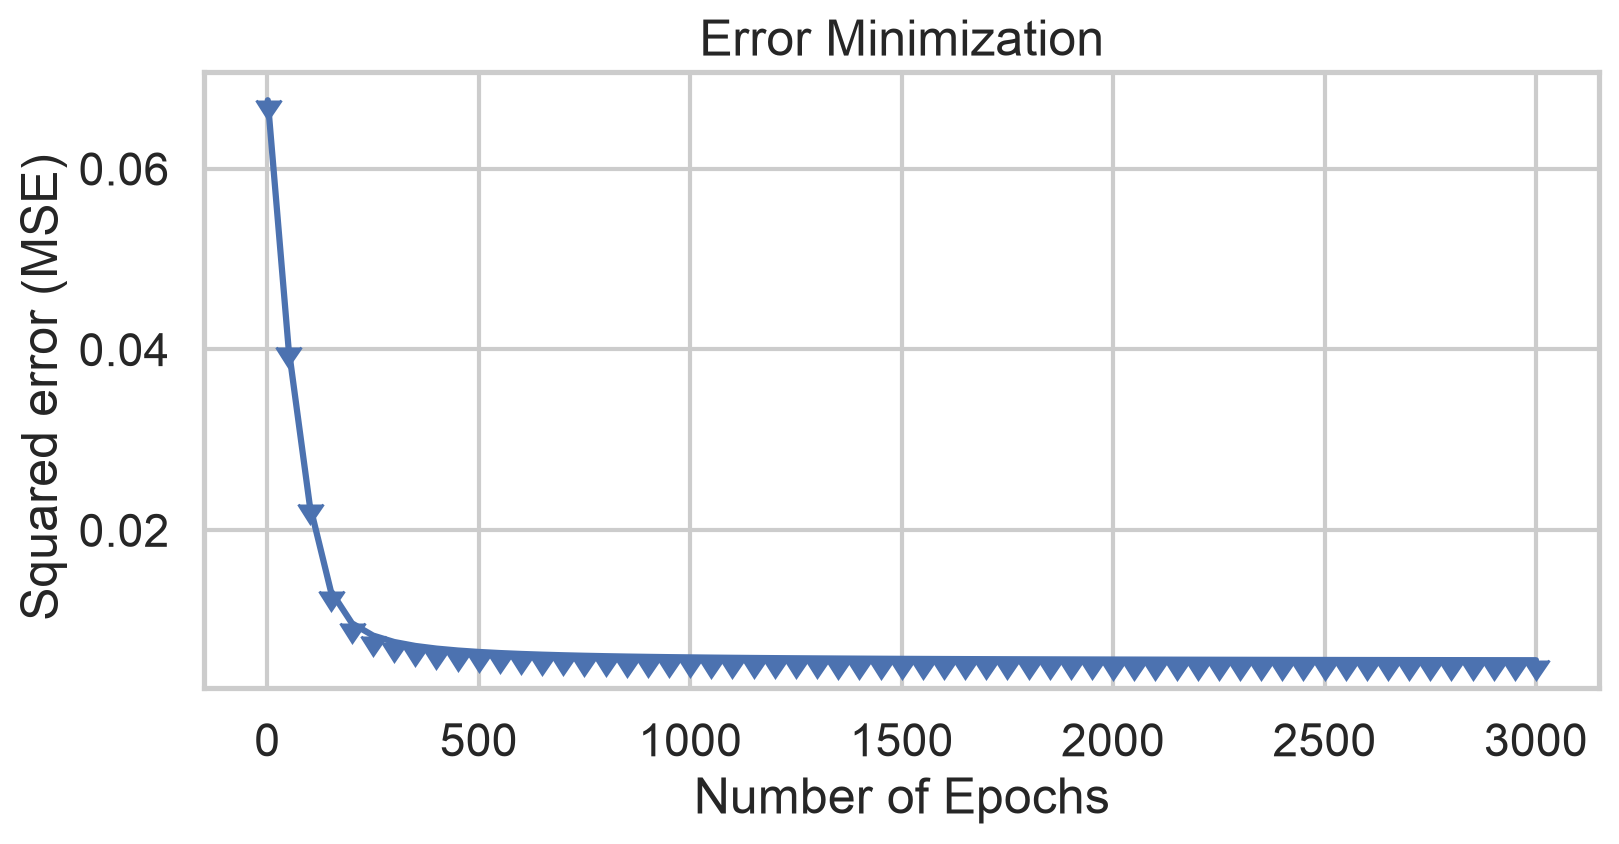

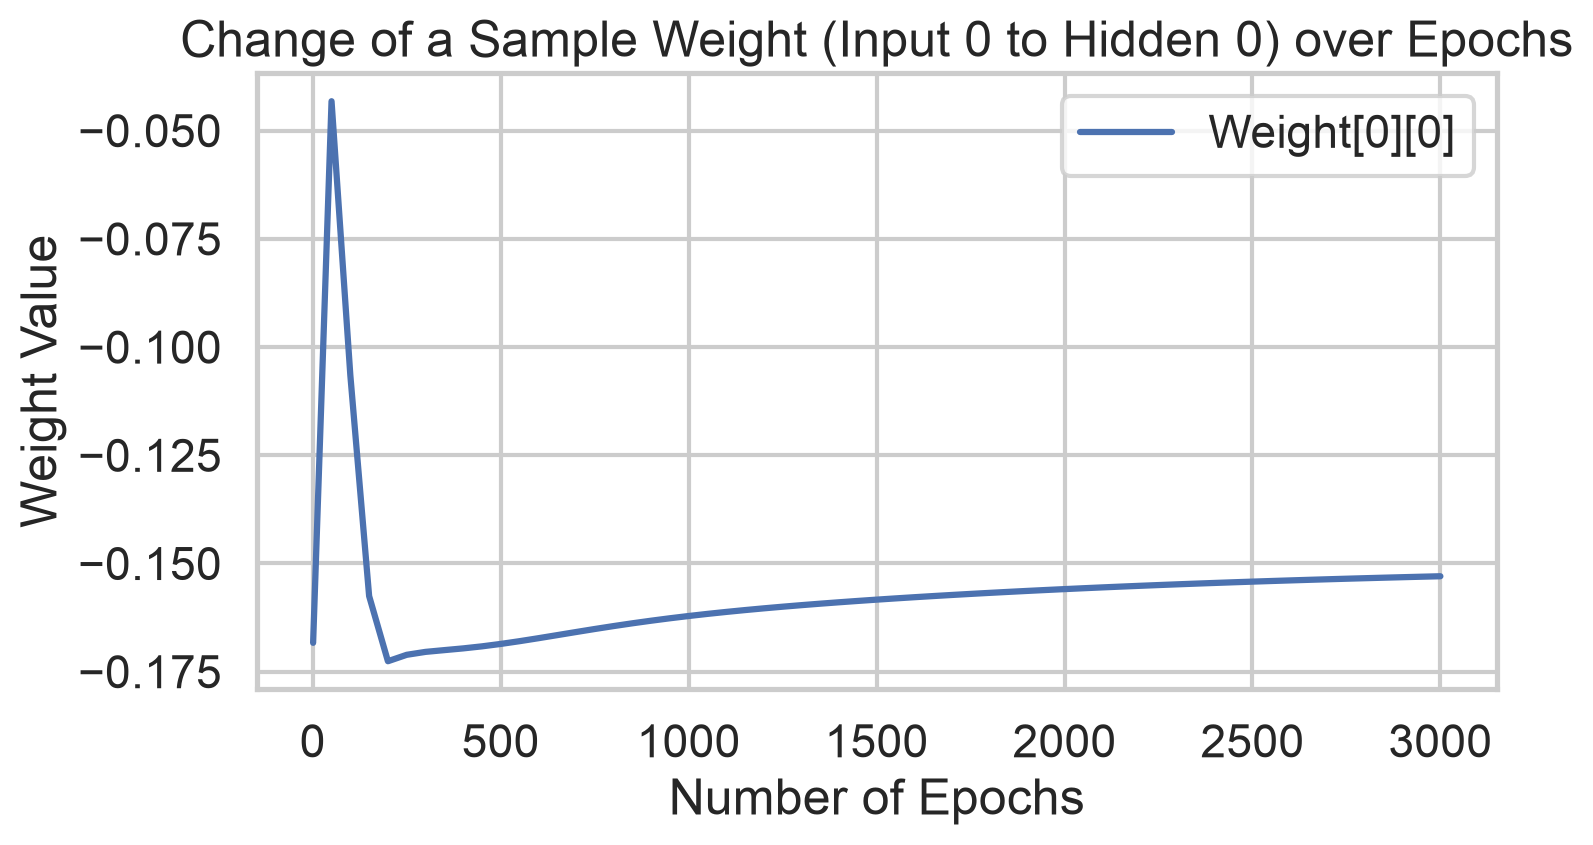

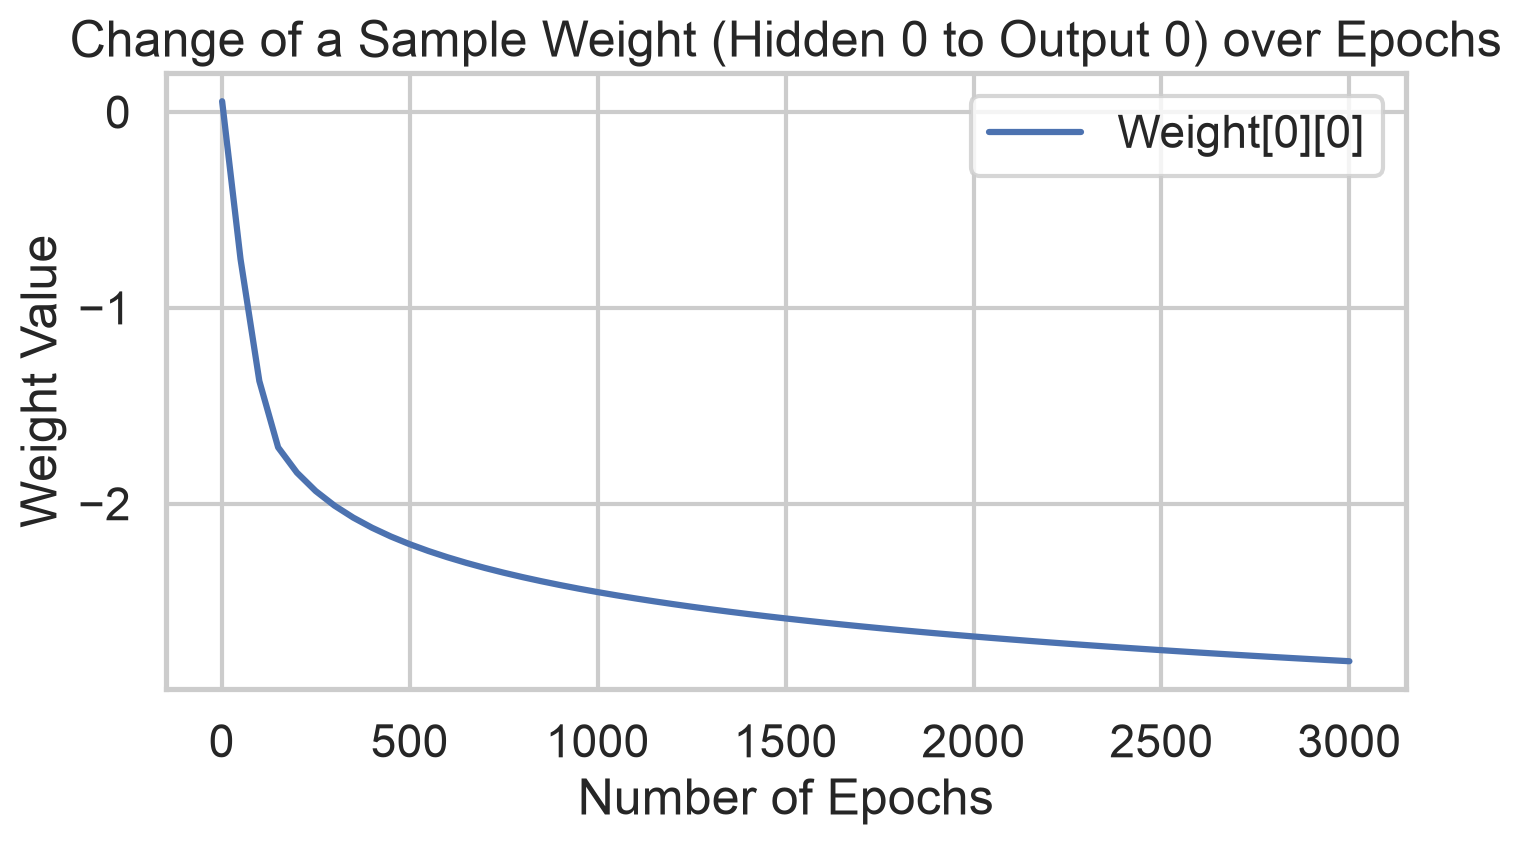

,params,"{'ActivationFunction': 'sigmoid', 'BiasHiddenValue': -1, 'BiasOutputValue': -1, 'Epocas': 3000, ...}"


In [10]:
dictionary = {'InputLayer':4, 'HiddenLayer':5, 'OutputLayer':3,
              'Epocas':3000, 'LearningRate':0.005,'BiasHiddenValue':-1,
              'BiasOutputValue':-1, 'ActivationFunction':'sigmoid'}

Perceptron = MultiLayerPerceptron(dictionary)
Perceptron.fit(train_X,train_y)

In [11]:
prev, dataframe = Perceptron.predict(test_X, test_y)
hits = n_set = n_vers = n_virg = 0
score_set = score_vers = score_virg = 0
for j in range(len(test_y)):
    if(test_y[j] == 0): n_set += 1
    elif(test_y[j] == 1): n_vers += 1
    elif(test_y[j] == 2): n_virg += 1

for i in range(len(test_y)):
    if test_y[i] == prev[i]:
        hits += 1
    if test_y[i] == prev[i] and test_y[i] == 0:
        score_set += 1
    elif test_y[i] == prev[i] and test_y[i] == 1:
        score_vers += 1
    elif test_y[i] == prev[i] and test_y[i] == 2:
        score_virg += 1

hits = (hits / len(test_y)) * 100
faults = 100 - hits

print("Porcents :","%.2f"%(hits),"% hits","and","%.2f"%(faults),"% faults")
print("Total samples of test",len(test_y))
print("*Iris-Setosa:",n_set,"samples", score_set, "hits")
print("*Iris-Versicolour:",n_vers,"samples", score_vers, "hits")
print("*Iris-Virginica:",n_virg,"samples", score_virg, "hits")

Porcents : 96.67 % hits and 3.33 % faults
Total samples of test 30
*Iris-Setosa: 20 samples 20 hits
*Iris-Versicolour: 9 samples 9 hits
*Iris-Virginica: 1 samples 0 hits


In [12]:
dataframe

,_id,class,output,hoped_output
0,0,Iris-setosa,0,0.0
1,1,Iris-setosa,0,0.0
2,2,Iris-setosa,0,0.0
3,3,Iris-versicolour,1,1.0
4,4,Iris-versicolour,1,1.0
5,5,Iris-setosa,0,0.0
6,6,Iris-versicolour,1,1.0
7,7,Iris-setosa,0,0.0
8,8,Iris-versicolour,1,1.0
9,9,Iris-setosa,0,0.0


- Acurracy Iris-Setosa: 100.00 %
- Acurracy Iris-Versicolour: 100.00 %
- Acurracy Iris-Virginica: 0.00 %


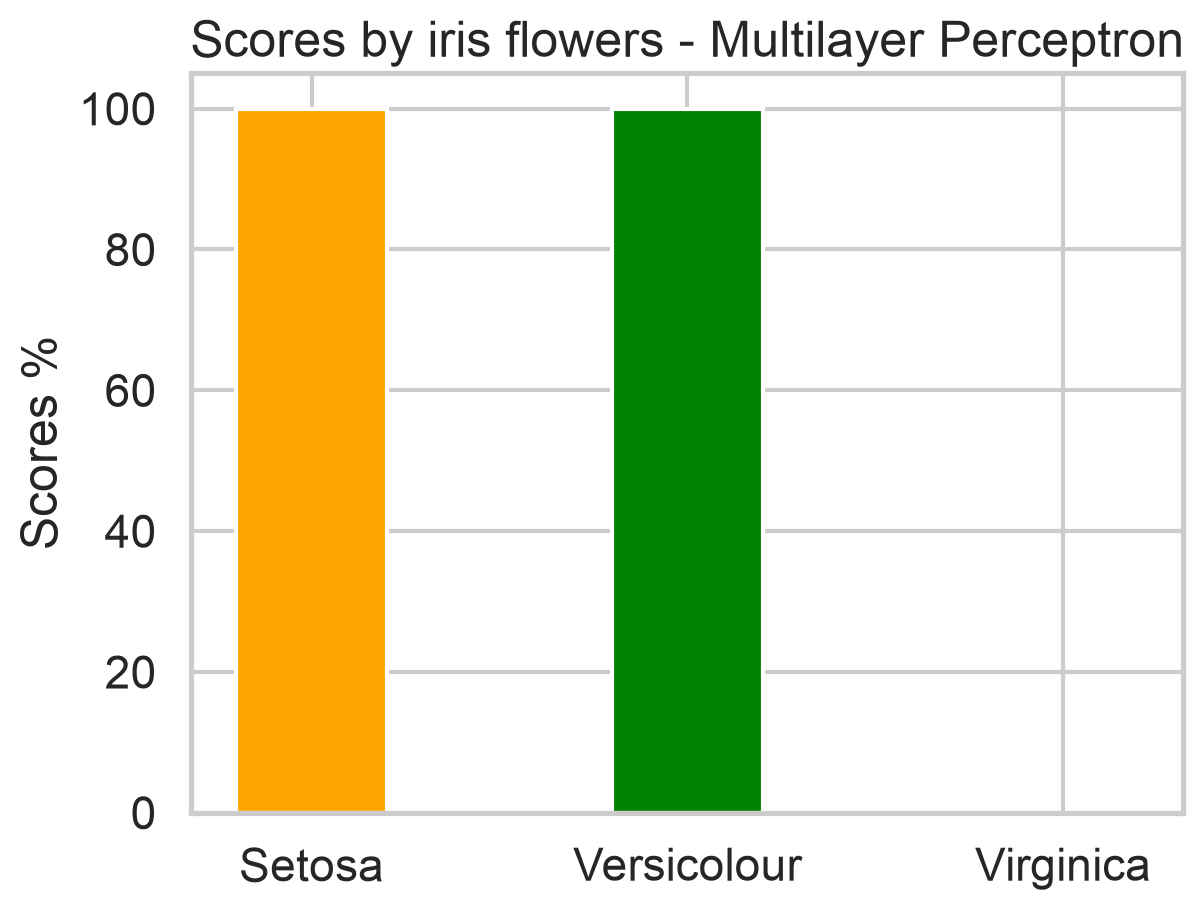

In [13]:
acc_set = (score_set/n_set)*100
acc_vers = (score_vers/n_vers)*100
acc_virg = (score_virg/n_virg)*100
print("- Acurracy Iris-Setosa:","%.2f"%acc_set, "%")
print("- Acurracy Iris-Versicolour:","%.2f"%acc_vers, "%")
print("- Acurracy Iris-Virginica:","%.2f"%acc_virg, "%")
names = ["Setosa","Versicolour","Virginica"]
x1 = [2.0,4.0,6.0]
fig, ax = plt.subplots()
r1 = plt.bar(x1[0], acc_set,color='orange',label='Iris-Setosa')
r2 = plt.bar(x1[1], acc_vers,color='green',label='Iris-Versicolour')
r3 = plt.bar(x1[2], acc_virg,color='purple',label='Iris-Virginica')
plt.ylabel('Scores %')
plt.xticks(x1, names);plt.title('Scores by iris flowers - Multilayer Perceptron')
plt.show()

# Improving the Notebook and results

## Class balance and robust evaluation

The original preparation shuffles a NumPy array of rows with `random.shuffle`; because NumPy rows are views, this can duplicate rows and skew the class counts. The section below compares that prepared array with a fresh, untouched Iris load, then uses a stratified split. In imbalanced data, the CV adapter oversamples minority classes inside each training fold only; validation and test folds keep their original distributions. Scaling is fitted separately inside each fold.

In [20]:
from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split

iris_reference = load_iris()
X_eval = iris_reference.data
y_eval = iris_reference.target
train_X_eval, test_X_eval, train_y_eval, test_y_eval = train_test_split(
    X_eval,
    y_eval,
    test_size=0.2,
    random_state=11,
    stratify=y_eval,
)

class_labels = np.arange(len(iris_reference.target_names))
source_counts = pd.Series(y_eval).value_counts().reindex(class_labels, fill_value=0)
prepared_counts = pd.Series(y).value_counts().reindex(class_labels, fill_value=0)
class_balance = pd.DataFrame({
    'class': iris_reference.target_names,
    'fresh_source_samples': source_counts.to_numpy(),
    'original_prepared_samples': prepared_counts.to_numpy(),
    'training_samples': pd.Series(train_y_eval).value_counts().reindex(class_labels, fill_value=0).to_numpy(),
    'test_samples': pd.Series(test_y_eval).value_counts().reindex(class_labels, fill_value=0).to_numpy(),
})
display(class_balance)

assert np.all(source_counts.to_numpy() == 50), 'Fresh Iris source should contain 50 samples per class.'
assert class_balance['training_samples'].nunique() == 1, 'The corrected stratified train split should preserve class counts.'
assert class_balance['test_samples'].nunique() == 1, 'The corrected stratified test split should preserve class counts.'

,class,fresh_source_samples,original_prepared_samples,training_samples,test_samples
0,setosa,50,102,40,10
1,versicolor,50,42,40,10
2,virginica,50,6,40,10


### Stratified 5-fold cross-validation

Each fold preserves class proportions. Minority-class oversampling happens only after a fold is assigned, preventing validation leakage. The scaler is also fitted within each training fold.

In [21]:
from contextlib import redirect_stdout
from io import StringIO
import random

from sklearn.base import BaseEstimator, ClassifierMixin
from sklearn.model_selection import StratifiedKFold, cross_validate
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler


class BalancedScratchMLP(ClassifierMixin, BaseEstimator):
    def __init__(self, params):
        self.params = params

    def fit(self, X, y):
        X = np.asarray(X)
        y = np.asarray(y)
        self.classes_ = np.unique(y)
        rng = np.random.default_rng(self.params.get('RandomState', 11))
        largest_class_size = max(np.count_nonzero(y == label) for label in self.classes_)
        balanced_indices = []

        for label in self.classes_:
            class_indices = np.flatnonzero(y == label)
            extra_indices = rng.choice(
                class_indices,
                size=largest_class_size - len(class_indices),
                replace=True,
            )
            balanced_indices.extend(np.concatenate([class_indices, extra_indices]))

        balanced_indices = np.asarray(balanced_indices)
        rng.shuffle(balanced_indices)
        random.seed(self.params.get('RandomState', 11))
        self.network_ = MultiLayerPerceptron(self.params)

        original_show = plt.show
        try:
            plt.show = lambda *args, **kwargs: None
            with redirect_stdout(StringIO()):
                self.network_.fit(X[balanced_indices], y[balanced_indices])
        finally:
            plt.show = original_show
            plt.close('all')
        self.balanced_class_counts_ = {
            label: np.count_nonzero(y[balanced_indices] == label)
            for label in self.classes_
        }
        return self

    def predict(self, X):
        dummy_labels = np.zeros(len(X), dtype=int)
        predictions, _ = self.network_.predict(X, dummy_labels)
        return np.asarray(predictions)


model_params = {
    'InputLayer': train_X_eval.shape[1],
    'HiddenLayer': 15,
    'OutputLayer': len(np.unique(train_y_eval)),
    'Epocas': 600,
    'LearningRate': 0.005,
    'BiasHiddenValue': -1,
    'BiasOutputValue': -1,
    'ActivationFunction': 'sigmoid',
    'RandomState': 42,
}

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
cv_pipeline = make_pipeline(StandardScaler(), BalancedScratchMLP(model_params))
cv_scores = cross_validate(
    cv_pipeline,
    train_X_eval,
    train_y_eval,
    cv=cv,
    scoring={
        'accuracy': 'accuracy',
        'balanced_accuracy': 'balanced_accuracy',
        'f1_macro': 'f1_macro',
    },
    return_train_score=False,
)

cv_summary = pd.DataFrame({
    'metric': ['accuracy', 'balanced_accuracy', 'f1_macro'],
    'mean': [cv_scores[f'test_{metric}'].mean() for metric in ['accuracy', 'balanced_accuracy', 'f1_macro']],
    'std': [cv_scores[f'test_{metric}'].std(ddof=1) for metric in ['accuracy', 'balanced_accuracy', 'f1_macro']],
})
display(cv_summary)
print('Per-fold accuracy:', np.round(cv_scores['test_accuracy'], 3))

,metric,mean,std
0,accuracy,0.775000,0.075691
1,balanced_accuracy,0.775000,0.075691
2,f1_macro,0.736068,0.105994


Per-fold accuracy: [0.833 0.708 0.875 0.75  0.708]


### Final holdout evaluation

After cross-validation, refit the same pipeline on the complete training split and evaluate once on the untouched test split. Report class-sensitive metrics and a confusion matrix alongside accuracy.

Imbalanced-fold training counts after oversampling: {np.int64(0): np.int64(15), np.int64(1): np.int64(15), np.int64(2): np.int64(15)}
Test accuracy: 0.867
Test balanced accuracy: 0.867
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       1.00      0.60      0.75        10
   virginica       0.71      1.00      0.83        10

    accuracy                           0.87        30
   macro avg       0.90      0.87      0.86        30
weighted avg       0.90      0.87      0.86        30



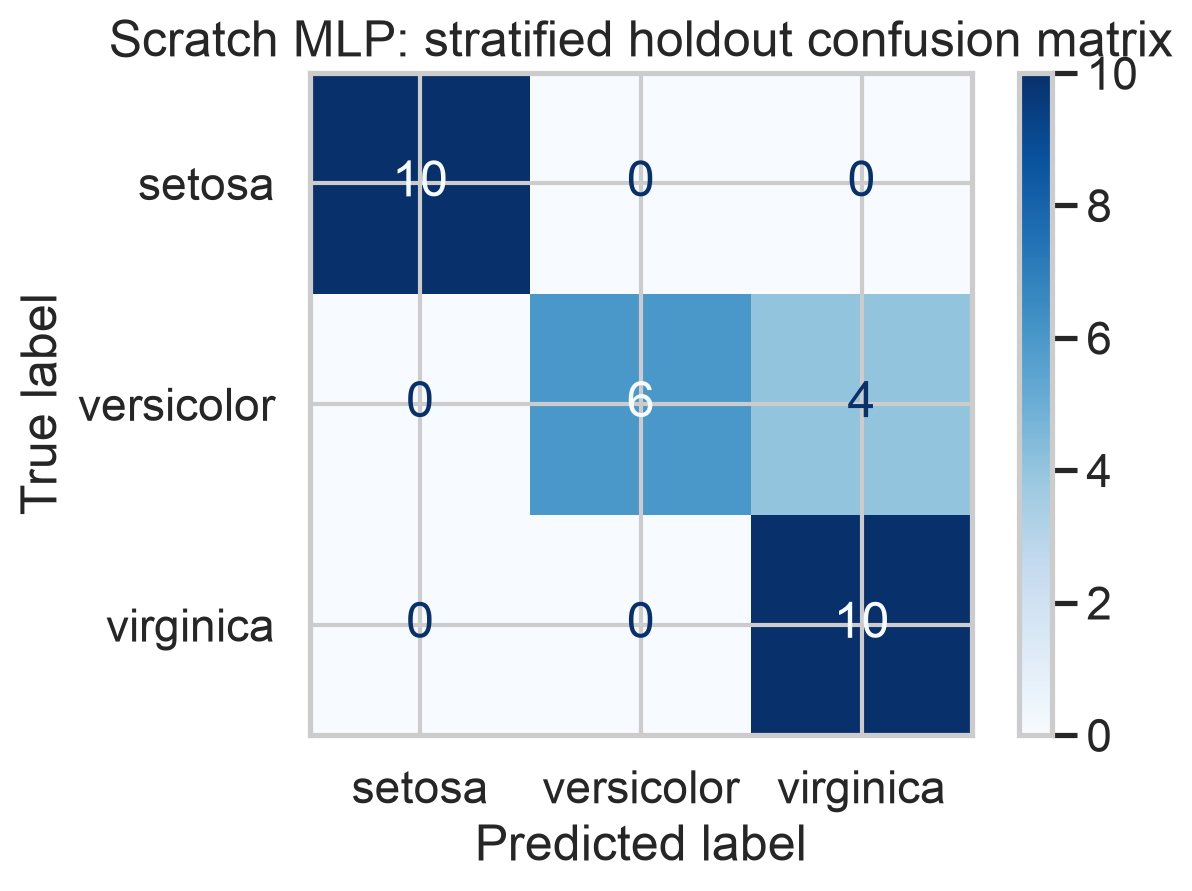

In [22]:
from sklearn.metrics import (
    ConfusionMatrixDisplay,
    accuracy_score,
    balanced_accuracy_score,
    classification_report,
)

probe_indices = np.concatenate([
    np.flatnonzero(y_eval == 0)[:15],
    np.flatnonzero(y_eval == 1)[:12],
    np.flatnonzero(y_eval == 2)[:3],
])
probe_params = dict(model_params, Epocas=1)
balance_probe = BalancedScratchMLP(probe_params).fit(X_eval[probe_indices], y_eval[probe_indices])
assert len(set(balance_probe.balanced_class_counts_.values())) == 1
print('Imbalanced-fold training counts after oversampling:', balance_probe.balanced_class_counts_)

final_pipeline = make_pipeline(StandardScaler(), BalancedScratchMLP(model_params))
final_pipeline.fit(train_X_eval, train_y_eval)
test_predictions = final_pipeline.predict(test_X_eval)
print(f'Test accuracy: {accuracy_score(test_y_eval, test_predictions):.3f}')
print(f'Test balanced accuracy: {balanced_accuracy_score(test_y_eval, test_predictions):.3f}')
print(classification_report(
    test_y_eval,
    test_predictions,
    labels=class_labels,
    target_names=iris_reference.target_names,
    zero_division=0,
))

ConfusionMatrixDisplay.from_predictions(
    test_y_eval,
    test_predictions,
    display_labels=iris_reference.target_names,
    cmap='Blues',
    values_format='d',
)
plt.title('Scratch MLP: stratified holdout confusion matrix')
plt.tight_layout()
plt.show()

# Step-by-step result improvements

Each stage below changes one part of the workflow while keeping the scratch perceptron unchanged. Model choices below use training-set cross-validation. The original notebook reports a test score before this section, so the later holdout comparison is illustrative rather than a pristine one-time estimate; for strict reporting, reserve a fresh test split before any evaluation.

The legacy-style row-shuffle result in Step 1 is a diagnostic reproduction, not a valid performance estimate: duplicated rows can appear in both training and validation folds, inflating scores. The corrected-data row is the meaningful CV estimate.

In [23]:
from sklearn.model_selection import cross_validate

experiment_metrics = {
    'accuracy': 'accuracy',
    'balanced_accuracy': 'balanced_accuracy',
    'f1_macro': 'f1_macro',
}
experiment_cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
step_results = []


def summarize_cv(stage, scores):
    return {
        'stage': stage,
        **{
            f'{metric}_mean': scores[f'test_{metric}'].mean()
            for metric in experiment_metrics
        },
        **{
            f'{metric}_std': scores[f'test_{metric}'].std(ddof=1)
            for metric in experiment_metrics
        },
    }


# Reproduce the old NumPy-row shuffle on training data only, keeping test data separate.
legacy_rows = np.column_stack((train_X_eval, train_y_eval)).copy()
random.seed(123)
random.shuffle(legacy_rows)
legacy_X = legacy_rows[:, :-1]
legacy_y = legacy_rows[:, -1].astype(int)
legacy_class_counts = pd.Series(legacy_y).value_counts().reindex(class_labels, fill_value=0)
print('Legacy-style training counts:', legacy_class_counts.to_dict())

legacy_cv_scores = cross_validate(
    make_pipeline(StandardScaler(), BalancedScratchMLP(model_params)),
    legacy_X,
    legacy_y,
    cv=experiment_cv,
    scoring=experiment_metrics,
    return_train_score=False,
)
clean_cv_scores = cross_validate(
    make_pipeline(StandardScaler(), BalancedScratchMLP(model_params)),
    train_X_eval,
    train_y_eval,
    cv=experiment_cv,
    scoring=experiment_metrics,
    return_train_score=False,
)
step_results.extend([
    summarize_cv('1. Legacy-style shuffled training rows', legacy_cv_scores),
    summarize_cv('1. Correct data preparation', clean_cv_scores),
])
display(pd.DataFrame(step_results).round(3))

Legacy-style training counts: {0: 55, 1: 31, 2: 34}


,stage,accuracy_mean,balanced_accuracy_mean,f1_macro_mean,accuracy_std,balanced_accuracy_std,f1_macro_std
0,1. Legacy-style shuffled training rows,0.792,0.732,0.688,0.042,0.056,0.084
1,1. Correct data preparation,0.775,0.775,0.736,0.076,0.076,0.106


## Step 2: Tune training settings with cross-validation

Compare a small predeclared parameter grid using macro-F1 on the training split only. This does not touch the held-out test set and does not modify the perceptron implementation.

In [25]:
from sklearn.model_selection import GridSearchCV

parameter_grid = [
    {
        'balancedscratchmlp__params': [
            dict(model_params, HiddenLayer=hidden_size, Epocas=epochs)
            for hidden_size in [5, 15]
            for epochs in [600, 1200]
        ]
    }
]
search = GridSearchCV(
    make_pipeline(StandardScaler(), BalancedScratchMLP(model_params)),
    parameter_grid,
    scoring='f1_macro',
    cv=experiment_cv,
    refit=True,
    n_jobs=1,
    return_train_score=False,
)
search.fit(train_X_eval, train_y_eval)

best_params = search.best_params_['balancedscratchmlp__params']
tuned_cv_scores = cross_validate(
    make_pipeline(StandardScaler(), BalancedScratchMLP(best_params)),
    train_X_eval,
    train_y_eval,
    cv=experiment_cv,
    scoring=experiment_metrics,
    return_train_score=False,
)
step_results.append(summarize_cv('2. CV-tuned scratch MLP', tuned_cv_scores))
print('Best parameters:', {
    'HiddenLayer': best_params['HiddenLayer'],
    'Epocas': best_params['Epocas'],
})
display(pd.DataFrame(step_results).round(3))

Best parameters: {'HiddenLayer': 5, 'Epocas': 600}


,stage,accuracy_mean,balanced_accuracy_mean,f1_macro_mean,accuracy_std,balanced_accuracy_std,f1_macro_std
0,1. Legacy-style shuffled training rows,0.792,0.732,0.688,0.042,0.056,0.084
1,1. Correct data preparation,0.775,0.775,0.736,0.076,0.076,0.106
2,2. CV-tuned scratch MLP,0.775,0.775,0.745,0.063,0.063,0.087


## Step 3: Measure split variability

Repeat stratified 5-fold evaluation with three fold seeds. The model and hyperparameters stay fixed; only the train/validation partitions change. This estimates sensitivity to data splitting, not uncertainty from all possible samples.

In [26]:
from sklearn.model_selection import RepeatedStratifiedKFold

repeated_cv = RepeatedStratifiedKFold(n_splits=5, n_repeats=3, random_state=42)
repeated_scores = cross_validate(
    make_pipeline(StandardScaler(), BalancedScratchMLP(best_params)),
    train_X_eval,
    train_y_eval,
    cv=repeated_cv,
    scoring=experiment_metrics,
    return_train_score=False,
)
step_results.append(summarize_cv('3. Tuned MLP, 3x repeated 5-fold CV', repeated_scores))
print('Repeated CV: 15 stratified validation folds')
display(pd.DataFrame(step_results).round(3))

Repeated CV: 15 stratified validation folds


,stage,accuracy_mean,balanced_accuracy_mean,f1_macro_mean,accuracy_std,balanced_accuracy_std,f1_macro_std
0,1. Legacy-style shuffled training rows,0.792,0.732,0.688,0.042,0.056,0.084
1,1. Correct data preparation,0.775,0.775,0.736,0.076,0.076,0.106
2,2. CV-tuned scratch MLP,0.775,0.775,0.745,0.063,0.063,0.087
3,"3. Tuned MLP, 3x repeated 5-fold CV",0.786,0.786,0.760,0.054,0.054,0.071


## Step 4: Compare established baselines

Evaluate a majority-class dummy classifier, logistic regression, and an RBF support vector machine on the same training folds. These are comparison points, not replacements for the scratch perceptron.

In [27]:
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC

baseline_models = {
    'Majority-class dummy': DummyClassifier(strategy='most_frequent'),
    'Logistic regression': make_pipeline(StandardScaler(), LogisticRegression(max_iter=2000)),
    'RBF SVM': make_pipeline(StandardScaler(), SVC(kernel='rbf')),
}
baseline_rows = []
for model_name, estimator in baseline_models.items():
    baseline_scores = cross_validate(
        estimator,
        train_X_eval,
        train_y_eval,
        cv=experiment_cv,
        scoring=experiment_metrics,
        return_train_score=False,
    )
    baseline_rows.append(summarize_cv(model_name, baseline_scores))

step_results.extend(baseline_rows)
display(pd.DataFrame(step_results).round(3))

,stage,accuracy_mean,balanced_accuracy_mean,f1_macro_mean,accuracy_std,balanced_accuracy_std,f1_macro_std
0,1. Legacy-style shuffled training rows,0.792,0.732,0.688,0.042,0.056,0.084
1,1. Correct data preparation,0.775,0.775,0.736,0.076,0.076,0.106
2,2. CV-tuned scratch MLP,0.775,0.775,0.745,0.063,0.063,0.087
3,"3. Tuned MLP, 3x repeated 5-fold CV",0.786,0.786,0.760,0.054,0.054,0.071
4,Majority-class dummy,0.333,0.333,0.167,0.000,0.000,0.000
5,Logistic regression,0.942,0.942,0.941,0.037,0.037,0.037
6,RBF SVM,0.942,0.942,0.942,0.023,0.023,0.022


## Step 5: Compare held-out results

Fit the selected scratch MLP and baselines on the complete training split, then compare them on the same test split. Do not tune based on these test scores. Because the original notebook already reported a score on this split, treat this table as illustrative; use a fresh reserved test set for a strict final estimate.

In [28]:
from sklearn.metrics import accuracy_score, balanced_accuracy_score, f1_score

final_models = {
    'CV-tuned scratch MLP': make_pipeline(StandardScaler(), BalancedScratchMLP(best_params)),
    **baseline_models,
}
holdout_rows = []
for model_name, estimator in final_models.items():
    estimator.fit(train_X_eval, train_y_eval)
    predictions = estimator.predict(test_X_eval)
    holdout_rows.append({
        'model': model_name,
        'accuracy': accuracy_score(test_y_eval, predictions),
        'balanced_accuracy': balanced_accuracy_score(test_y_eval, predictions),
        'macro_f1': f1_score(test_y_eval, predictions, average='macro'),
    })

holdout_comparison = pd.DataFrame(holdout_rows).sort_values('macro_f1', ascending=False)
display(holdout_comparison.round(3))

,model,accuracy,balanced_accuracy,macro_f1
2,Logistic regression,1.000,1.000,1.000
3,RBF SVM,1.000,1.000,1.000
0,CV-tuned scratch MLP,0.867,0.867,0.861
1,Majority-class dummy,0.333,0.333,0.167
